# Screen playlist analysis
Your own curated subset of the repertoire playlist. Joined back to `songs_final.csv` by exact Spotify `track_id` (via `songs_metadata.csv`), so genre/year/etc. come straight from the pipeline - no fuzzy matching needed.

In [1]:
import sys
sys.path.insert(0, "..")
import pandas as pd
import matplotlib.pyplot as plt
from src import preferences

# preferences.report() fetches the screen playlist live, joins it to
# songs_final.csv by track_id, and fetches Last.fm genres for anything
# outside the repertoire - same logic src.preferences uses from the CLI.
df, unmatched = preferences.report()
matched = df[df["line_no"].notna()]

[preferences report] 225 tracks in the screen playlist
[preferences report] 193/248 matched to the repertoire by track_id (10 more recovered via ISRC catalog-duplicate check)
[preferences report] 140/193 matched songs have a genre from the pipeline
[preferences report] 28/55 unmatched songs got a genre from Last.fm directly


## Unmatched tracks
Not found in songs_metadata.csv by track_id - either not from the repertoire, or its Spotify match changed since.

In [2]:
unmatched_tracks = df[df["line_no"].isna()][["name", "artist"]]
unmatched_tracks.to_csv("../data/processed/playlist_review_unmatched.csv", index=False)
unmatched_tracks

,name,artist
6,Bombon Asesino,Alma Bella De Nilver Huarac
19,Tienes La Magia,Lil Silvio & El Vega
20,Si o No,Victor Muñoz
21,Como Le Gusta a Tu Cuerpo (feat. Michel Teló),"Carlos Vives, Michel Teló"
23,He Llorado (Como Un Niño),"Juan Magán, Gente De Zona"
26,Conteo Regresivo - Salsa Version,Gilberto Santa Rosa
31,Cervecero,Armonía 10 de Walther Lozada
32,Cuando Acaba el Placer,"Los 4, Mayco D' Alma"
35,A Llorar a Otra Parte,Hnos Yaipén
37,Cuando tu no estas,Olga Tañón


## Genre coverage

In [3]:
matched = df[df["line_no"].notna()]
n_missing = matched["genre"].isna().sum()
n_pipeline = len(matched) - n_missing
n_lastfm = unmatched["genre"].notna().sum()
print(f"{n_pipeline}/{len(matched)} matched songs have a genre from the pipeline")
print(f"{n_lastfm}/{len(unmatched)} unmatched songs got a genre from Last.fm directly")
print(f"{n_pipeline + n_lastfm}/{len(df)} total rows with a genre, all sources combined")

140/193 matched songs have a genre from the pipeline
28/55 unmatched songs got a genre from Last.fm directly
168/248 total rows with a genre, all sources combined


## Songs still missing a genre

Two groups, two different fixes:
- **Matched songs** (have a `line_no`): edit `data/dictionaries/genre_overrides.json` (artist -> `{"genre": ..., "subgenre": ...}`, same as the existing `Grupo 5` entry), then re-run `python -m src.genre_analysis`.
- **Unmatched songs** (no `line_no`, not in the repertoire pipeline at all): fill in the `genre` column of the exported CSV below by hand, save it, then re-run the next cell to reload it.

In [4]:
matched_missing = matched[matched["genre"].isna()][["line_no", "name", "artist"]]
matched_missing.to_csv("../data/processed/playlist_review_matched_missing_genre.csv", index=False)
print(f"{len(matched_missing)} matched songs still missing a genre -> fix via genre_overrides.json (see above)")
matched_missing

53 matched songs still missing a genre -> fix via genre_overrides.json (see above)


,line_no,name,artist
3,117.0,Boogie Wonderland (with The Emotions),"Earth, Wind & Fire, The Emotions"
4,667.0,Boogie Wonderland (with The Emotions),"Earth, Wind & Fire, The Emotions"
8,116.0,Bonita Si E´,"Donny Caballero, Chelito De Castro"
14,132.0,Caballo Viejo,"Roberto Torres, Charanga Vallenata"
17,158.0,Carmelina,Merengues Dorados
22,193.0,Como Mirarte,Josimar y Su Yambú
27,217.0,Corazón Abierto,Victor Muñoz
28,748.0,Corazón Abierto,Victor Muñoz
29,219.0,Corazón,Giuliana Rengifo
34,231.0,Cuando Nos Volvamos a Encontrar (feat. Marc An...,"Carlos Vives, Marc Anthony"


In [5]:
import os

FILL_CSV = "../data/processed/playlist_review_unmatched_missing_genre.csv"

still_missing = unmatched[unmatched["genre"].isna()][["name", "artist"]].copy()

if os.path.exists(FILL_CSV):
    filled = pd.read_csv(FILL_CSV, keep_default_na=False)
    filled = filled[filled["genre"] != ""].drop_duplicates(subset=["name", "artist"])
    # left-merge on the deduped fill list preserves unmatched's row order/count 1:1,
    # so this Series can be safely re-indexed onto unmatched before filling nulls.
    merged_genre = unmatched.merge(filled, on=["name", "artist"], how="left", suffixes=("", "_filled"))["genre_filled"]
    unmatched["genre"] = unmatched["genre"].fillna(pd.Series(merged_genre.values, index=unmatched.index))
    still_missing = unmatched[unmatched["genre"].isna()][["name", "artist"]].copy()
    print(f"reloaded {len(filled)} hand-filled genres from {FILL_CSV}")

still_missing["genre"] = ""  # fill this column by hand, save, re-run this cell
still_missing.to_csv(FILL_CSV, index=False)
print(f"{len(still_missing)} unmatched songs still need a genre -> fill in {FILL_CSV}, save, re-run this cell")
still_missing

reloaded 0 hand-filled genres from ../data/processed/playlist_review_unmatched_missing_genre.csv
27 unmatched songs still need a genre -> fill in ../data/processed/playlist_review_unmatched_missing_genre.csv, save, re-run this cell


,name,artist,genre
6,Bombon Asesino,Alma Bella De Nilver Huarac,
20,Si o No,Victor Muñoz,
21,Como Le Gusta a Tu Cuerpo (feat. Michel Teló),"Carlos Vives, Michel Teló",
23,He Llorado (Como Un Niño),"Juan Magán, Gente De Zona",
31,Cervecero,Armonía 10 de Walther Lozada,
32,Cuando Acaba el Placer,"Los 4, Mayco D' Alma",
35,A Llorar a Otra Parte,Hnos Yaipén,
38,Kulikitaka Ti,Merengue Latin Band,
44,Mi declaración,Bigal & L Jake,
49,Dile la Verdad,Pamela Franco,


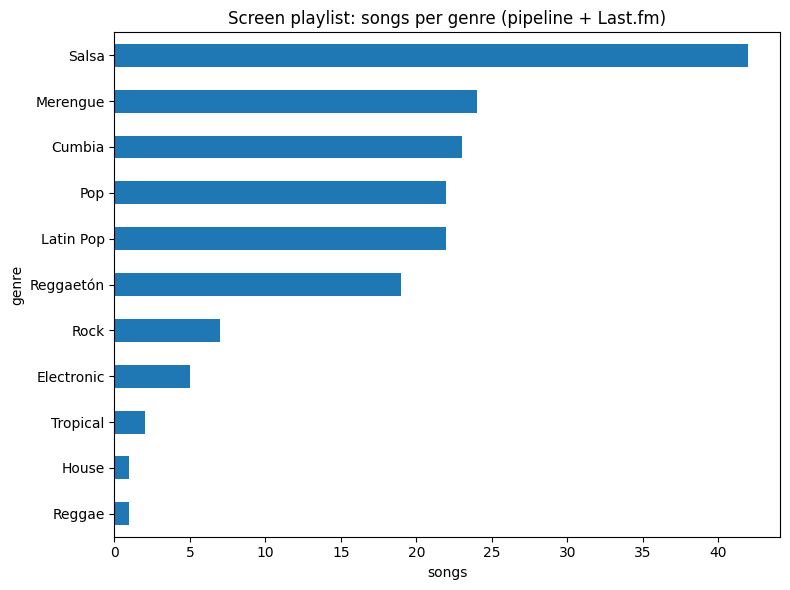

In [6]:
genre_counts = matched["genre"].value_counts().add(unmatched["genre"].value_counts(), fill_value=0).sort_values(ascending=False)
genre_counts.plot(kind="barh", figsize=(8, 6), title="Screen playlist: songs per genre (pipeline + Last.fm)")
plt.gca().invert_yaxis()
plt.xlabel("songs")
plt.tight_layout()
plt.show()

## Songs per decade
Pipeline-matched songs only - the Last.fm-only tracks don't have a `year` (that comes from Spotify's `songs_metadata.csv`, which we never queried for them).

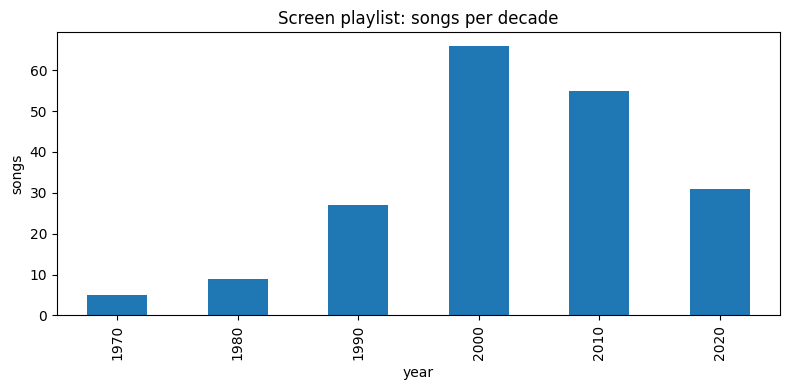

In [7]:
decade = (matched["year"].dropna() // 10 * 10).astype(int)
decade.value_counts().sort_index().plot(kind="bar", figsize=(8, 4), title="Screen playlist: songs per decade")
plt.ylabel("songs")
plt.tight_layout()
plt.show()

## Genre by decade

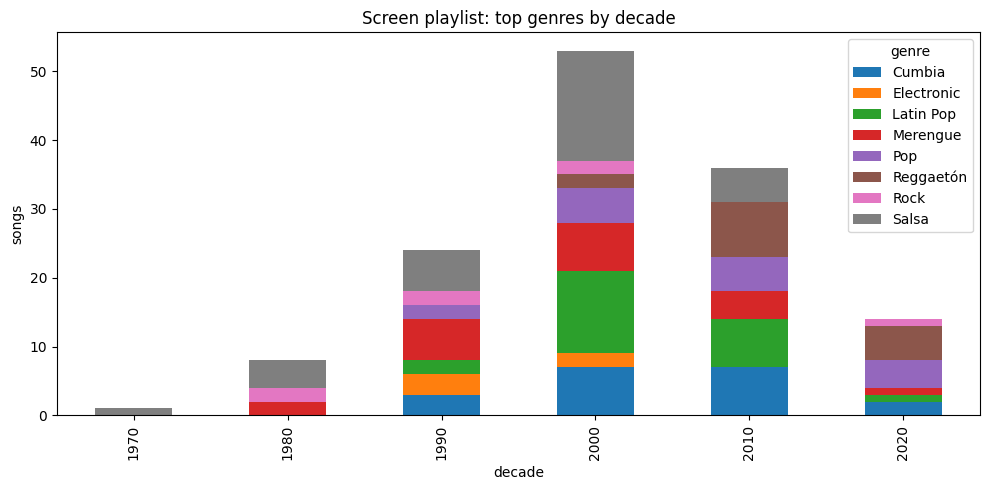

In [8]:
top_genres = genre_counts.head(8).index
pivot = matched.assign(decade=decade).query("genre in @top_genres").pivot_table(
    index="decade", columns="genre", values="name", aggfunc="count", fill_value=0
)
pivot.plot(kind="bar", stacked=True, figsize=(10, 5), title="Screen playlist: top genres by decade")
plt.ylabel("songs")
plt.tight_layout()
plt.show()